Computing recurrence intervals with IMERG time series at Hunt, Texas\
July 2025 Flood Event

Extreme value analysis (EVA) method: Block Maxima (BM)

Jacob R. Schaperow - jacob.r.schaperow@nasa.gov\
Andrew M. Fisher - andrew.m.fisher@nasa.gov\
Ariana L. McDermott - ariana.m.louise@nasa.gov\

In [68]:
# Import packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pyextremes import EVA

In [56]:
# Import time series data

df = pd.read_csv('./Data/hunt_texas_IMERG_daily.txt')
df.columns = ['date','precip_mm']
print(df.head())

ds_series = df.set_index('date')['precip_mm']
print(ds_series.head())

ds_series.index = pd.to_datetime(ds_series.index)

         date  precip_mm
0  1998-01-01      0.000
1  1998-01-02      0.000
2  1998-01-03      0.085
3  1998-01-04      0.000
4  1998-01-05      0.000
date
1998-01-01    0.000
1998-01-02    0.000
1998-01-03    0.085
1998-01-04    0.000
1998-01-05    0.000
Name: precip_mm, dtype: float64


In [57]:
# Clean data by removing zeros

df_noz = ds_series[ds_series>0]
print(df_noz.head())
print(len(df_noz))
print(len(ds_series))

date
1998-01-03     0.085
1998-01-06    27.195
1998-01-07     0.755
1998-01-20     0.260
1998-01-22     1.305
Name: precip_mm, dtype: float64
3221
10135


date
1998-10-06    107.755
1999-06-13     58.355
2000-10-23     68.595
2001-11-15     94.000
2002-07-04     98.555
Name: precip_mm, dtype: float64


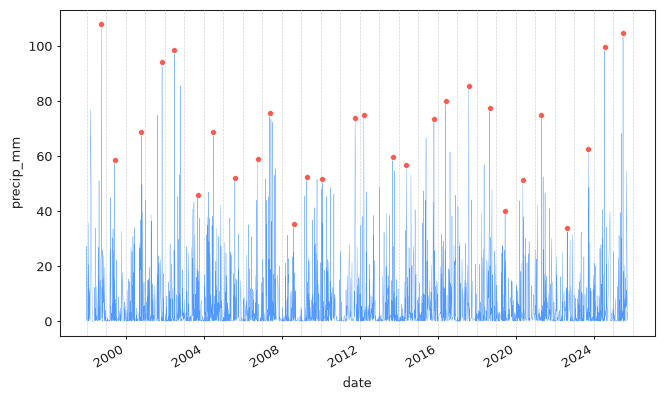

In [58]:
# Creating a model for the time series data using the Block Maxima (BM) method

model = EVA(df_noz)
model.get_extremes(method = "BM", block_size="365.2425D")
print(model.extremes.head())
model.plot_extremes()
plt.show()

                           Univariate Extreme Value Analysis                            
                                      Source Data                                       
----------------------------------------------------------------------------------------
Data label:                     precip_mm      Size:                               3,221
Start:                       January 1998      End:                       September 2025
                                     Extreme Values                                     
----------------------------------------------------------------------------------------
Count:                                 28      Extraction method:                     BM
Type:                                high      Block size:             365 days 05:49:12
                                         Model                                          
----------------------------------------------------------------------------------------
Model:               

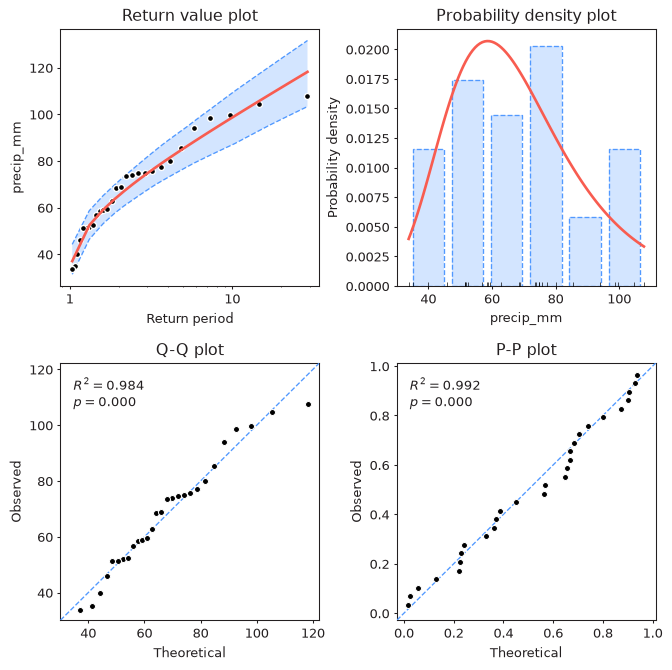

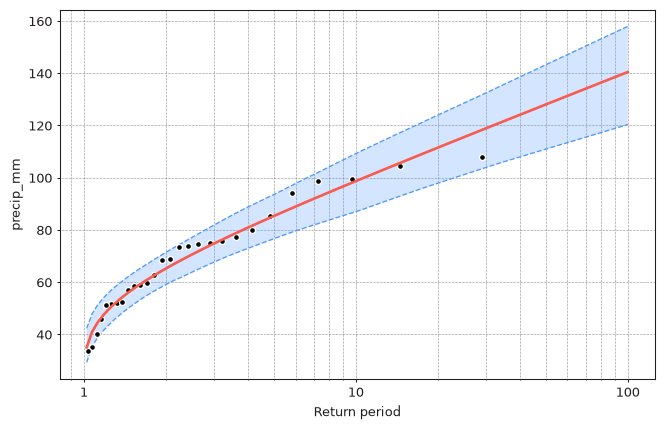

In [59]:
# Fit a model to the extreme values

model.fit_model() # default fitting method is MLE - Maximum Likelihood Estimate 
print(model)

model.plot_diagnostic(alpha=0.95)

model.plot_return_values(
    return_period = np.logspace(0.01,2,100),
    alpha = 0.95
)
plt.show()

In [67]:
# Estimate return values

summary = model.get_summary(
    return_period=[1, 2, 5, 10, 25, 45, 50, 100],
    alpha=0.95,
    n_samples=100,
)
print(summary)

               return value    lower ci    upper ci
return period                                      
1.0                    -inf         NaN         NaN
2.0               65.164572   59.011547   71.345296
5.0               85.310969   76.614378   93.569529
10.0              98.649637   86.962623  109.198558
25.0             115.503079  101.144627  128.544821
45.0             126.113063  109.470694  140.969416
50.0             128.005925  110.903187  143.208396
100.0            140.416452  120.295310  157.888241


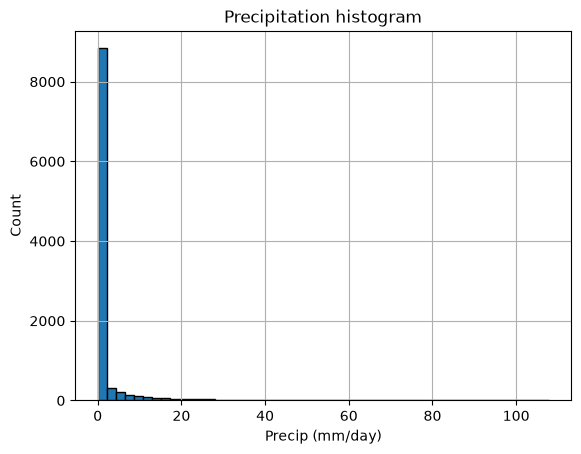

In [61]:
# Plot histogram (with zeros)

df['precip_mm'].hist(bins = 50, edgecolor='black')
plt.title('Precipitation histogram')
plt.xlabel('Precip (mm/day)')
plt.ylabel('Count')
plt.show()

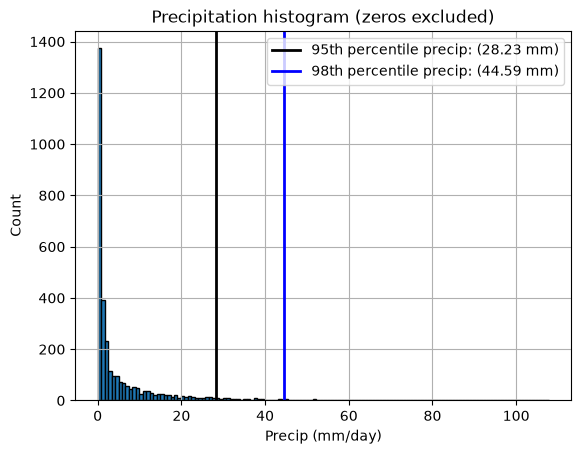

In [64]:
# Plot histogram (without zeros)

df_noz = df[df['precip_mm']>0]
p95 = np.percentile(df_noz['precip_mm'], 95) # calculate 95% precipitation
p98 = np.percentile(df_noz['precip_mm'], 98) # calculate 98% precipitation

df_noz['precip_mm'].hist(bins = "fd", edgecolor='black')
plt.axvline(x = p95, 
    color = "black", 
    linewidth = 2, 
    label=f"95th percentile precip: ({p95:.2f} mm)"
)
plt.axvline(x = p98, 
    color = "blue", 
    linewidth = 2, 
    label=f"98th percentile precip: ({p98:.2f} mm)"
)

plt.title('Precipitation histogram (zeros excluded)')
plt.xlabel('Precip (mm/day)')
plt.ylabel('Count')
plt.legend()
plt.show()